In [9]:
import pandas as pd

files = [
    "FIFA_WC2026_Groups_A_B_C.xlsx",
    "FIFA_WC2026_Groups_D_E_F_xG_Shots.xlsx",
    "DATA of G-H-I.xlsx",
    "Group J-L Analysis.xlsx"
]

for file in files:
    excel_file = pd.ExcelFile(file)
    print(file)
    print(excel_file.sheet_names)
    print()

FIFA_WC2026_Groups_A_B_C.xlsx
['README', 'Team-Match Data', 'Team Summary']

FIFA_WC2026_Groups_D_E_F_xG_Shots.xlsx
['README', 'Team-Match Data', 'Team Summary']

DATA of G-H-I.xlsx
['README', 'Team-Match Data', 'Team Summary']

Group J-L Analysis.xlsx
['groups_JKL_raw_data', 'groups_JKL_team_summary']



In [10]:
import pandas as pd

abc = pd.read_excel(
    "FIFA_WC2026_Groups_A_B_C.xlsx",
    sheet_name="Team-Match Data"
)

def_data = pd.read_excel(
    "FIFA_WC2026_Groups_D_E_F_xG_Shots.xlsx",
    sheet_name="Team-Match Data"
)

ghi = pd.read_excel(
    "DATA of G-H-I.xlsx",
    sheet_name="Team-Match Data"
)

jkl = pd.read_excel(
    "Group J-L Analysis.xlsx",
    sheet_name="groups_JKL_raw_data"
)

print("A-B-C columns:")
print(abc.columns.tolist())

print("\nD-E-F columns:")
print(def_data.columns.tolist())

print("\nG-H-I columns:")
print(ghi.columns.tolist())

print("\nJ-K-L columns:")
print(jkl.columns.tolist())

A-B-C columns:
['Group', 'Match', 'Date', 'Team', 'Opponent', 'Attempts at Goal', 'xG', 'xG per Shot', 'Outcome', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']

D-E-F columns:
['Group', 'Match', 'Date', 'Team', 'Opponent', 'Attempts at Goal', 'xG', 'xG per Shot', 'Outcome']

G-H-I columns:
['Group', 'Match', 'Date', 'Team', 'Opponent', 'Attempts at Goal', 'xG', 'xG per Shot', 'Outcome', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11']

J-K-L columns:
['Group', 'Match_ID', 'Team', 'Opponent', 'Shots', 'xG', 'Data_Source', 'Advanced']


In [19]:
import pandas as pd


# 1. Remove unwanted Unnamed columns


abc = abc.loc[:, ~abc.columns.str.startswith("Unnamed")]
ghi = ghi.loc[:, ~ghi.columns.str.startswith("Unnamed")]



# 2. Rename J-K-L columns


jkl = jkl.rename(columns={
    "Match_ID": "Match",
    "Shots": "Attempts at Goal"
})



# 3. Convert Advanced column to Outcome


def convert_outcome(value):
    value = str(value).strip().lower()

    if value in ["true", "1", "yes", "y", "advanced", "qualified"]:
        return "Advanced"

    elif value in ["false", "0", "no", "n", "eliminated", "not advanced"]:
        return "Eliminated"

    else:
        return value


jkl["Outcome"] = jkl["Advanced"].apply(convert_outcome)

# 4. J-K-L has no Date column


jkl["Date"] = pd.NaT


# 5. Keep only columns needed


columns_needed = [
    "Group",
    "Match",
    "Date",
    "Team",
    "Opponent",
    "Attempts at Goal",
    "xG",
    "Outcome"
]

abc_clean = abc[columns_needed].copy()
def_clean = def_data[columns_needed].copy()
ghi_clean = ghi[columns_needed].copy()
jkl_clean = jkl[columns_needed].copy()


# 6. Combine all four datasets


df = pd.concat(
    [abc_clean, def_clean, ghi_clean, jkl_clean],
    ignore_index=True
)



# 7. Make sure shots and xG are numeric


df["Attempts at Goal"] = pd.to_numeric(
    df["Attempts at Goal"],
    errors="coerce"
)

df["xG"] = pd.to_numeric(
    df["xG"],
    errors="coerce"
)

# 8. Calculate xG per Shot in PYTHON


df["xG per Shot"] = (
    df["xG"] /
    df["Attempts at Goal"]
)


# Put columns in nice order

df = df[
    [
        "Group",
        "Match",
        "Date",
        "Team",
        "Opponent",
        "Attempts at Goal",
        "xG",
        "xG per Shot",
        "Outcome"
    ]
]


print(df.head())

  Group Match                 Date            Team        Opponent  \
0     A   M01  2026-06-11 00:00:00          Mexico    South Africa   
1     A   M01  2026-06-11 00:00:00    South Africa          Mexico   
2     A   M02  2026-06-11 00:00:00  Korea Republic         Czechia   
3     A   M02  2026-06-11 00:00:00         Czechia  Korea Republic   
4     A   M25  2026-06-18 00:00:00         Czechia    South Africa   

   Attempts at Goal    xG  xG per Shot     Outcome  
0                16  1.78     0.111250    Advanced  
1                 3  0.10     0.033333    Advanced  
2                15  1.77     0.118000  Eliminated  
3                 7  0.64     0.091429  Eliminated  
4                14  1.36     0.097143  Eliminated  


In [1]:
## Data Validation

In [21]:
print("Dataset size:")
print(df.shape)

print("\nNumber of teams:")
print(df["Team"].nunique())

print("\nRows in each group:")
print(df["Group"].value_counts().sort_index())

Dataset size:
(144, 9)

Number of teams:
48

Rows in each group:
Group
A    12
B    12
C    12
D    12
E    12
F    12
G    12
H    12
I    12
J    12
K    12
L    12
Name: count, dtype: int64


In [22]:
team_matches = df.groupby("Team").size()

print(team_matches)

Team
Algeria                   3
Argentina                 3
Australia                 3
Austria                   3
Belgium                   3
Bosnia and Herzegovina    3
Brazil                    3
Canada                    3
Cape Verde                3
Colombia                  3
Congo DR                  3
Croatia                   3
Curaçao                   3
Czechia                   3
Côte d'Ivoire             3
Ecuador                   3
Egypt                     3
England                   3
France                    3
Germany                   3
Ghana                     3
Haiti                     3
Iran                      3
Iraq                      3
Japan                     3
Jordan                    3
Korea Republic            3
Mexico                    3
Morocco                   3
Netherlands               3
New Zealand               3
Norway                    3
Panama                    3
Paraguay                  3
Portugal                  3
Qatar          

In [23]:
print(team_matches.value_counts())

3    48
Name: count, dtype: int64


In [24]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:")
print(duplicates)

Number of duplicate rows:
0


In [25]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Group                0
Match                0
Date                36
Team                 0
Opponent             0
Attempts at Goal     0
xG                   0
xG per Shot          0
Outcome              0
dtype: int64


In [26]:
important_columns = [
    "Group",
    "Team",
    "Opponent",
    "Attempts at Goal",
    "xG",
    "Outcome"
]

print(df[important_columns].isnull().sum())

Group               0
Team                0
Opponent            0
Attempts at Goal    0
xG                  0
Outcome             0
dtype: int64


In [27]:
print(df["Outcome"].value_counts())

Outcome
Advanced      96
Eliminated    48
Name: count, dtype: int64


In [28]:
print("Negative shots:")
print((df["Attempts at Goal"] < 0).sum())

print("Negative xG:")
print((df["xG"] < 0).sum())

Negative shots:
0
Negative xG:
0


### Validation Interpretation

The combined dataset contained 144 team-match observations representing 48 teams, with three group-stage observations for each team. The important analysis variables contained no missing values or duplicate records, and no invalid negative values were identified for xG or Attempts at Goal.

Values extracted from the source data were also checked against the official FIFA post-match summary reports before analysis. These validation steps were used to reduce the risk of data-entry or extraction errors.

In [29]:
team_summary = (
    df.groupby(["Group", "Team", "Outcome"], as_index=False)
      .agg(
          Matches=("Team", "size"),
          Total_Attempts=("Attempts at Goal", "sum"),
          Total_xG=("xG", "sum")
      )
)

team_summary["xG_per_Shot"] = (
    team_summary["Total_xG"] /
    team_summary["Total_Attempts"]
)

print(team_summary)

   Group                    Team     Outcome  Matches  Total_Attempts  \
0      A                 Czechia  Eliminated        3              34   
1      A          Korea Republic  Eliminated        3              32   
2      A                  Mexico    Advanced        3              35   
3      A            South Africa    Advanced        3              33   
4      B  Bosnia and Herzegovina    Advanced        3              27   
5      B                  Canada    Advanced        3              59   
6      B                   Qatar  Eliminated        3              17   
7      B             Switzerland    Advanced        3              45   
8      C                  Brazil    Advanced        3              40   
9      C                   Haiti  Eliminated        3              31   
10     C                 Morocco    Advanced        3              48   
11     C                Scotland  Eliminated        3              29   
12     D               Australia    Advanced       

In [30]:
print(team_summary.shape)

(48, 7)


In [31]:
team_summary.head(10)

,Group,Team,Outcome,Matches,Total_Attempts,Total_xG,xG_per_Shot
0,A,Czechia,Eliminated,3,34,2.44,0.071765
1,A,Korea Republic,Eliminated,3,32,3.38,0.105625
2,A,Mexico,Advanced,3,35,4.22,0.120571
3,A,South Africa,Advanced,3,33,2.33,0.070606
4,B,Bosnia and Herzegovina,Advanced,3,27,1.83,0.067778
5,B,Canada,Advanced,3,59,7.00,0.118644
6,B,Qatar,Eliminated,3,17,1.89,0.111176
7,B,Switzerland,Advanced,3,45,6.67,0.148222
8,C,Brazil,Advanced,3,40,6.19,0.154750
9,C,Haiti,Eliminated,3,31,1.61,0.051935


In [32]:
print(team_summary["Outcome"].value_counts())

Outcome
Advanced      32
Eliminated    16
Name: count, dtype: int64


In [33]:
advanced_population = team_summary[
    team_summary["Outcome"] == "Advanced"
]

eliminated_population = team_summary[
    team_summary["Outcome"] == "Eliminated"
]

advanced_sample = advanced_population.sample(
    n=24,
    random_state=42
)

eliminated_sample = eliminated_population.sample(
    n=12,
    random_state=42
)

sample_df = pd.concat(
    [advanced_sample, eliminated_sample],
    ignore_index=True
)

print("Population size:", len(team_summary))
print("Sample size:", len(sample_df))

print("\nSample groups:")
print(sample_df["Outcome"].value_counts())

Population size: 48
Sample size: 36

Sample groups:
Outcome
Advanced      24
Eliminated    12
Name: count, dtype: int64


In [34]:
advanced = sample_df[
    sample_df["Outcome"] == "Advanced"
]["xG_per_Shot"]

eliminated = sample_df[
    sample_df["Outcome"] == "Eliminated"
]["xG_per_Shot"]

summary_stats = (
    sample_df
    .groupby("Outcome")["xG_per_Shot"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std_Dev="std",
        Minimum="min",
        Maximum="max"
    )
)

print(summary_stats)

            Count      Mean    Median   Std_Dev   Minimum   Maximum
Outcome                                                            
Advanced       24  0.111539  0.106674  0.034593  0.054348  0.183429
Eliminated     12  0.087113  0.086902  0.017468  0.060000  0.111176


In [35]:
from scipy import stats
import numpy as np

def confidence_interval(data, confidence=0.95):
    n = len(data)
    mean = np.mean(data)
    standard_error = stats.sem(data)

    margin_error = stats.t.ppf(
        (1 + confidence) / 2,
        df=n - 1
    ) * standard_error

    lower = mean - margin_error
    upper = mean + margin_error

    return mean, lower, upper


advanced_ci = confidence_interval(advanced)
eliminated_ci = confidence_interval(eliminated)

print("Advanced teams")
print("Mean:", round(advanced_ci[0], 4))
print("95% CI:", round(advanced_ci[1], 4), "to", round(advanced_ci[2], 4))

print("\nEliminated teams")
print("Mean:", round(eliminated_ci[0], 4))
print("95% CI:", round(eliminated_ci[1], 4), "to", round(eliminated_ci[2], 4))

Advanced teams
Mean: 0.1115
95% CI: 0.0969 to 0.1261

Eliminated teams
Mean: 0.0871
95% CI: 0.076 to 0.0982


## Statistical Assumptions

In [36]:
advanced = sample_df[
    sample_df["Outcome"] == "Advanced"
]["xG_per_Shot"]

eliminated = sample_df[
    sample_df["Outcome"] == "Eliminated"
]["xG_per_Shot"]

In [37]:
from scipy import stats

shapiro_advanced = stats.shapiro(advanced)
shapiro_eliminated = stats.shapiro(eliminated)

print("Advanced teams:")
print("Shapiro-Wilk statistic =", round(shapiro_advanced.statistic, 4))
print("p-value =", round(shapiro_advanced.pvalue, 4))

print("\nEliminated teams:")
print("Shapiro-Wilk statistic =", round(shapiro_eliminated.statistic, 4))
print("p-value =", round(shapiro_eliminated.pvalue, 4))

Advanced teams:
Shapiro-Wilk statistic = 0.963
p-value = 0.5023

Eliminated teams:
Shapiro-Wilk statistic = 0.9479
p-value = 0.606


##Assumption Interpretation

The Shapiro-Wilk test showed no significant evidence of non-normality for either group. The advanced teams had a p-value of 0.5023 and the eliminated teams had a p-value of 0.6060, both greater than 0.05. Therefore, the normality assumption was considered reasonable for this analysis.

Each team contributed one team-level xG-per-shot value, so observations were treated as independent. Welch's two-sample t-test was used because it does not require the two groups to have equal variances.

In [38]:
t_stat, p_value = stats.ttest_ind(
    advanced,
    eliminated,
    equal_var=False
)

print("Welch Two-Sample t-test")
print("t-statistic:", round(t_stat, 4))
print("p-value:", round(p_value, 4))

Welch Two-Sample t-test
t-statistic: 2.8151
p-value: 0.0081


### T-Test Interpretation

The Welch two-sample t-test produced a t-statistic of 2.8151 and a p-value of 0.0081. Since the p-value is less than 0.05, the null hypothesis was rejected. This provides evidence of a statistically significant difference in mean xG per shot between advanced and eliminated teams. Advanced teams had the higher sample mean, indicating that they generally created higher-quality scoring chances during the group stage.

C:\Users\arysh\AppData\Local\Temp\ipykernel_27192\487441991.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


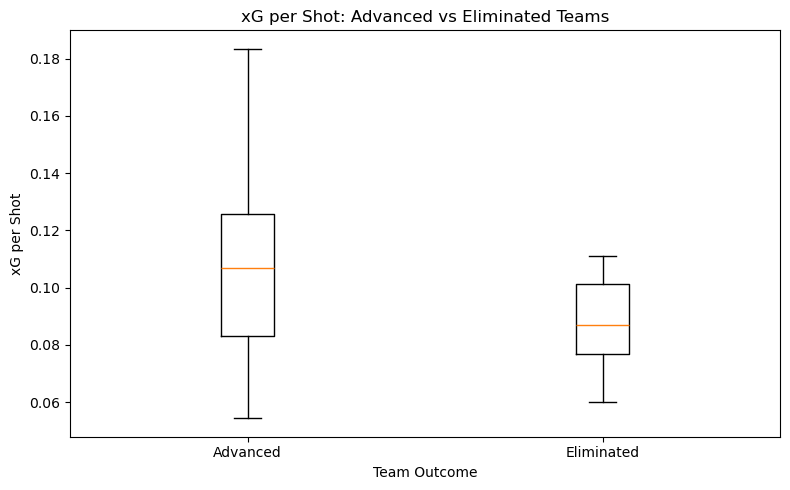

In [39]:
import matplotlib.pyplot as plt

advanced_values = sample_df[
    sample_df["Outcome"] == "Advanced"
]["xG_per_Shot"]

eliminated_values = sample_df[
    sample_df["Outcome"] == "Eliminated"
]["xG_per_Shot"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [advanced_values, eliminated_values],
    labels=["Advanced", "Eliminated"]
)

plt.title("xG per Shot: Advanced vs Eliminated Teams")
plt.xlabel("Team Outcome")
plt.ylabel("xG per Shot")

plt.tight_layout()
plt.savefig(
    "xG_per_shot_advanced_vs_eliminated.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Limitations
This analysis uses xG values produced by FIFA's expected-goals model, so the results depend on the assumptions and methodology of that model.

The analysis shows an association between xG per shot and advancement, but it does not prove that higher xG per shot caused teams to advance. Other factors such as finishing ability, defending, goalkeeper performance, and match context may also affect tournament progression.

## Overall Conclusion

Advanced teams had a higher mean xG per shot than eliminated teams during the FIFA World Cup 2026 group stage. The Welch two-sample t-test showed that this difference was statistically significant (p = 0.0081).

This suggests that teams that advanced generally created higher-quality scoring chances. However, the result should be interpreted as an association rather than evidence that higher xG per shot caused advancement.

In [42]:
# Save the full 144-row raw dataset
df.to_csv(
    "FIFA_WC2026_All_Groups_Raw_Data.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save the 48-team prepared dataset
team_summary.to_csv(
    "FIFA_WC2026_Team_Summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save the 36-team analysis sample
sample_df.to_csv(
    "FIFA_WC2026_Analysis_Sample.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Files saved successfully with Excel-compatible encoding.")

Files saved successfully with Excel-compatible encoding.
